In [15]:
import numpy as np
import matplotlib.pyplot as plt
from bat_hd.random_walk import generate_bat_flight
from bat_hd.plot_tools import angular_error, smooth_ts
from bat_hd.bat_hd_system import (
    HeadDirectionNetwork,
    BatHeadDirectionSystem,
    BatHDSystemConfig,
)
import os

plt.rcParams.update(
    {
        "font.family": "Helvetica",
        "font.size": 12,
    }
)
PLOTS_DIR = "../plots/compare_torus"
os.makedirs(PLOTS_DIR, exist_ok=True)

In [2]:
T = 400
dt = 0.5e-3
intrinsic_noise = 0.01
input_noise = 0.1
interval = 100
n_seeds = 10

torus_results = []
rings_results = []
bat_flight_results = []

for seed in range(n_seeds):
    bat_flight = generate_bat_flight(T, dt, seed=seed)

    bat_flight_results.append(bat_flight)

    config = BatHDSystemConfig(
        dt=dt,
        n_ring=(2**8, 2**7),
        intrinsic_noise=intrinsic_noise,
        input_noise=input_noise,
        feedback_mode="none",
        size=1 / 3,
    )

    bat_hd_system = BatHeadDirectionSystem(config, seed=seed)
    bat_hd_system.warm_up(initial_dir=bat_flight["dir_torus"][0])
    rings_results.append(bat_hd_system.run_simulation(bat_flight, interval=interval))

    torus_system = HeadDirectionNetwork(
        dt=dt,
        n=(2**4, 2**4),
        intrinsic_noise=intrinsic_noise,
        input_noise=input_noise,
        size=1 / 3,
        seed=seed,
    )
    torus_system.warm_up(initial_dir=bat_flight["dir_torus"][0])
    torus_results.append(torus_system.run_simulation(bat_flight, interval=interval))

Running Simulation Steps: 100%|██████████| 800000/800000 [01:55<00:00, 6952.22it/s] 


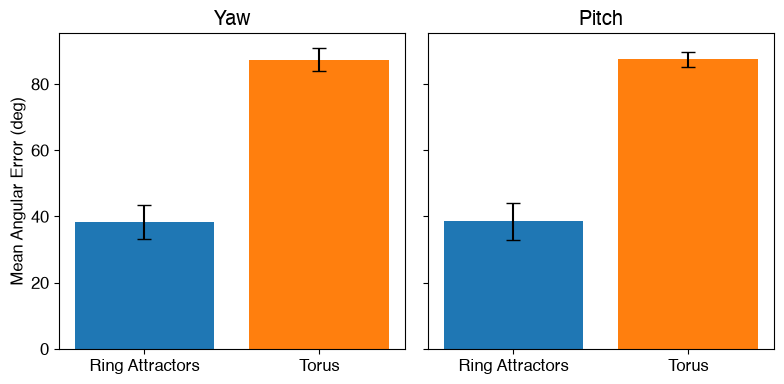

In [17]:
smooth_interval = 10
n_seeds = len(torus_results)
torus_angular_errors = []
rings_angular_errors = []
for i in range(n_seeds):
    torus_angular_errors.append(
        np.mean(
            np.abs(
                angular_error(
                    bat_flight_results[i]["dir_torus"][::interval],
                    torus_results[i]["decoded_angle"],
                )
            ),
            axis=0,
        )
    )
    rings_angular_errors.append(
        np.mean(
            np.abs(
                angular_error(
                    bat_flight_results[i]["dir_torus"][::interval],
                    rings_results[i]["decoded_angle"],
                )
            ),
            axis=0,
        )
    )

torus_angular_errors = np.array(torus_angular_errors)
rings_angular_errors = np.array(rings_angular_errors)
mean_torus_angular_errors = np.mean(torus_angular_errors, axis=0)
std_torus_angular_errors = np.std(torus_angular_errors, axis=0) / np.sqrt(n_seeds)
mean_rings_angular_errors = np.mean(rings_angular_errors, axis=0)
std_rings_angular_errors = np.std(rings_angular_errors, axis=0) / np.sqrt(n_seeds)

fig, ax = plt.subplots(ncols=2, figsize=(8, 4), sharey=True)
for i in range(2):
    ax[i].bar(
        ["Ring Attractors", "Torus"],
        [mean_rings_angular_errors[i], mean_torus_angular_errors[i]],
        yerr=[std_rings_angular_errors[i], std_torus_angular_errors[i]],
        capsize=5,
        color=plt.cm.tab10(np.arange(2)),
    )
    ax[i].set_title("Yaw" if i == 0 else "Pitch")
ax[0].set_ylabel("Mean Angular Error (deg)")

fig.tight_layout()
fig.savefig(f"{PLOTS_DIR}/angular_error_comparison.svg")

Generating bat flight: 100%|██████████| 799999/799999 [00:56<00:00, 14214.12it/s]


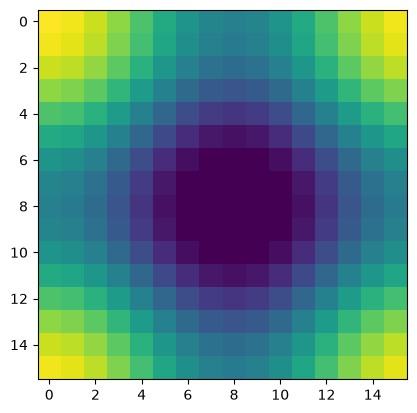

In [ ]:
seed = 0

bat_flight = generate_bat_flight(T, dt)

bat_flight_results.append(bat_flight)

config = BatHDSystemConfig(
    dt=dt,
    n_ring=(2**8, 2**7),
    intrinsic_noise=intrinsic_noise,
    input_noise=input_noise,
    feedback_mode="none",
    size=1 / 3,
)

bat_hd_system = BatHeadDirectionSystem(config, seed=seed)
bat_hd_system.warm_up(initial_dir=bat_flight["dir_torus"][0])

torus_system = HeadDirectionNetwork(
    dt=dt,
    n=(2**4, 2**4),
    intrinsic_noise=intrinsic_noise,
    input_noise=input_noise,
    size=1 / 3,
)
torus_system.warm_up(initial_dir=bat_flight["dir_torus"][0])